# 02 · Customer Segmentation (RFM)

**Goal:** group customers by how recently, how often and how much they buy, and find the top 10%.

- **R**ecency: days since the customer's last order (lower = better)
- **F**requency: number of unique orders
- **M**onetary: total sales

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("../data")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Load the cleaned data

Load `data/processed/superstore_clean.csv` from notebook 01, parsing the date columns.

In [46]:
df = pd.read_csv(DATA_DIR / "processed" /"superstore_clean.csv", parse_dates=["Order Date", "Ship Date"])
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Day,Ship Days,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,8,3,0.1600
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,8,3,0.3000
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,12,4,0.4700
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,11,7,-0.4000
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,11,7,0.1125


## 2. Build the RFM table

- Snapshot date = the last order date in the data + 1 day
- Group by `Customer ID` to get Recency, Frequency and Monetary for each customer

In [47]:
snapshot_date = df["Order Date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Last_Order=("Order Date", "max"),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum"),
)

rfm["Recency"] = (snapshot_date - rfm["Last_Order"]).dt.days

rfm.head()

,Last_Order,Frequency,Monetary,Recency
Customer ID,,,,
AA-10315,2017-06-29,5,5563.560,185
AA-10375,2017-12-11,9,1056.390,20
AA-10480,2017-04-15,4,1790.512,260
AA-10645,2017-11-05,6,5086.935,56
AB-10015,2016-11-10,3,886.156,416


## 3. Score each customer 1–5

Each metric is split into 5 equal-sized groups with `pd.qcut`.
- Recency: **fewer** days = **higher** score
- Frequency and Monetary: higher = higher score

Many customers have the same number of orders, so Frequency is ranked first to break ties.

In [48]:
rfm["R_Score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm.head()

,Last_Order,Frequency,Monetary,Recency,R_Score,F_Score,M_Score
Customer ID,,,,,,,
AA-10315,2017-06-29,5,5563.560,185,2,2,5
AA-10375,2017-12-11,9,1056.390,20,5,5,2
AA-10480,2017-04-15,4,1790.512,260,1,1,3
AA-10645,2017-11-05,6,5086.935,56,3,3,5
AB-10015,2016-11-10,3,886.156,416,1,1,1


## 4. Name the segments

Scores run from 1 to 5 (5 = best). Rules are checked top to bottom, and each customer gets the first segment that matches.

| Segment | Rule | Who they are |
|---|---|---|
| Champions | R ≥ 4, F ≥ 4, M ≥ 4 | Recent, frequent, high-spending |
| Loyal Customers | R ≥ 3, F ≥ 4 | Buy often and are still active |
| Big Spenders | M = 5 | Top 20% by spend who don't qualify as Champions or Loyal |
| Can't Lose Them | R ≤ 2, F ≥ 4 | Used to buy often but have gone quiet |
| At Risk | R ≤ 2, F = 3 | Average buyers who have gone quiet |
| New Customers | R ≥ 4, F ≤ 2 | Bought recently, only 1–2 orders |
| Lost Customers | R ≤ 2, F ≤ 2 | Bought rarely, and long ago |
| Others | everyone else | Middle of the pack |

In [49]:
def segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 4:
        return "Loyal Customers"
    elif m == 5:
        return "Big Spenders"
    elif r <= 2 and f >= 4:
        return "Can't Lose Them"
    elif r <= 2 and f == 3:
        return "At Risk"
    elif r >= 4 and f <= 2:
        return "New Customers"
    elif r <= 2 and f <= 2:
        return "Lost Customers"
    else:
        return "Others"

rfm["Segment"] = rfm.apply(segment, axis=1)
rfm["Segment"].value_counts()

Segment
Lost Customers     161
Loyal Customers    131
Others             127
Champions          106
New Customers       84
Big Spenders        80
At Risk             59
Can't Lose Them     45
Name: count, dtype: int64

## 5. Top 10% customers

The top 10% of customers by total sales, and their share of total sales and profit.

In [50]:
top_n = int(len(rfm) * 0.10)
top10 = rfm.nlargest(top_n, "Monetary")

print(f"Top 10% = {top_n} customers")
top10.head(10)

Top 10% = 79 customers


,Last_Order,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,Segment
Customer ID,,,,,,,,
SM-20320,2017-10-12,5,25043.050,80,3,2,5,Big Spenders
TC-20980,2016-11-26,5,19052.218,400,1,2,5,Big Spenders
RB-19360,2017-09-25,6,15117.339,97,3,3,5,Big Spenders
TA-21385,2017-10-22,4,14595.620,70,3,2,5,Big Spenders
AB-10105,2017-11-19,10,14473.571,42,4,5,5,Champions
KL-16645,2017-11-13,12,14175.229,48,4,5,5,Champions
SC-20095,2017-01-15,9,14142.334,350,1,5,5,Big Spenders
HL-15040,2017-11-17,6,12873.298,44,4,3,5,Big Spenders
SE-20110,2017-12-21,11,12209.438,10,5,5,5,Champions


In [51]:
top_rows = df[df["Customer ID"].isin(top10.index)]

sales_share = top_rows["Sales"].sum() / df["Sales"].sum() * 100
profit_share = top_rows["Profit"].sum() / df["Profit"].sum() * 100

print(f"Top 10% of customers bring in {sales_share:.1f}% of sales")
print(f"Top 10% of customers bring in {profit_share:.1f}% of profit")

Top 10% of customers bring in 30.6% of sales
Top 10% of customers bring in 42.6% of profit


## 6. Charts

- Number of customers per segment (bar chart)
- Sales per segment (bar chart)

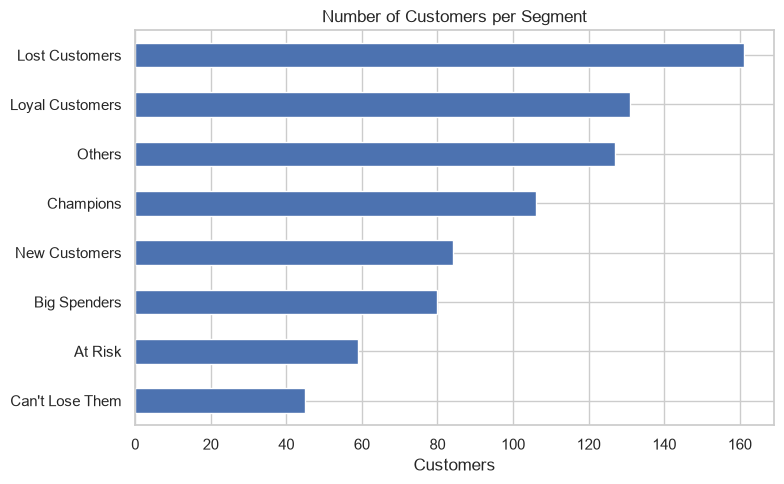

In [52]:
counts = rfm["Segment"].value_counts()

counts.plot(kind="barh", figsize=(8, 5))
plt.title("Number of Customers per Segment")
plt.xlabel("Customers")
plt.ylabel("")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../reports/figures/customer_segments.png", dpi=300)
plt.show()

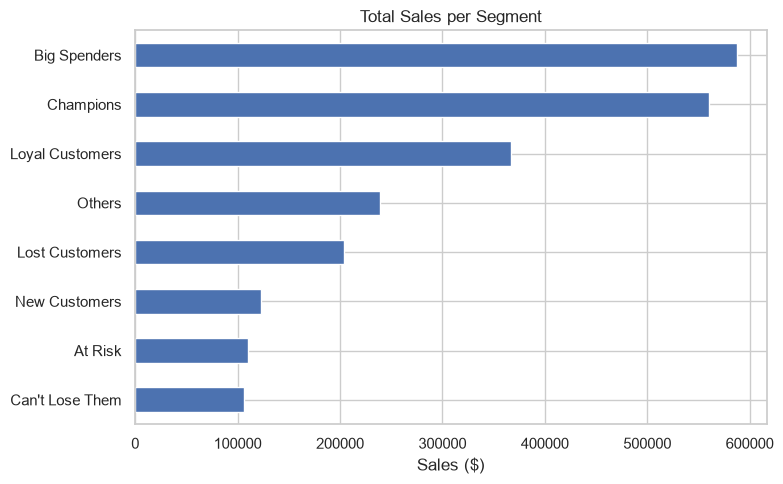

In [53]:
sales = rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False)

sales.plot(kind="barh", figsize=(8, 5))
plt.title("Total Sales per Segment")
plt.xlabel("Sales ($)")
plt.ylabel("")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../reports/figures/sales_per_segment.png", dpi=300)
plt.show()

## 7. Save

Saved to `data/processed/customer_segments.csv`.

In [54]:
rfm.to_csv(DATA_DIR / "processed" / "customer_segments.csv")

## Takeaways

**Revenue is concentrated:** the top 10% of customers (79 people) bring in 30.6% of sales and 42.6% of profit.

| Segment | Customers | Share of sales | What the business should do |
|---|---|---|---|
| Big Spenders | 80 | 26% | The highest-value group, but their last order was about 170 days ago on average. Personal outreach to win them back before they lapse. |
| Champions | 106 | 24% | Reward and retain: loyalty perks, early access, a dedicated contact. |
| Loyal Customers | 131 | 16% | Upsell and cross-sell to move them up to Champions. |
| New Customers | 84 | 5% | Follow up after the first order with an incentive for a second purchase. |
| Can't Lose Them / At Risk | 104 | 9% | Regular buyers who went quiet 7–8 months ago. Targeted win-back emails, keeping any discount at 20% or less (larger discounts usually lose money, see notebook 01). |
| Lost Customers | 161 | 9% | The largest group but low value. Low-cost reactivation only. |
| Others | 127 | 10% | Monitor; include in regular campaigns. |